# Week 4: Exercise 1 - Modin (Pandas on Ray)

**GOAL:** Learn to increase the speed of Pandas workflows by changing a single line of code.

[Modin](https://modin.readthedocs.io/en/latest/?badge=latest) (Pandas on Ray) is a project aimed at speeding up Pandas using Ray.

### Using Modin

To use Modin, only a single line of code must be changed.

Simply change:
```python
import pandas as pd
```
to
```python
import modin.pandas as pd
```

Changing this line of code will allow you to use all of the cores in your machine to do computation on your data. One of the major performance bottlenecks of Pandas is that it only uses a single core for any given computation. **Modin** exposes an API that is identical to Pandas, allowing you to continue interacting with your data as you would with Pandas. **There are no additional commands required to use Modin locally.** Partitioning, scheduling, data transfer, and other related concerns are all handled by **Modin** and **Ray** under the hood.

### Concept for Exercise: DataFrame Constructor

Often when playing around in Pandas, it is useful to create a DataFrame with the constructor. That is where we will start.

```python
import numpy as np
import pandas as pd

frame_data = np.random.randint(0, 100, size=(2**10, 2**5))
df = pd.DataFrame(frame_data)
```

The above code creates a Pandas DataFrame full of random integers with 1024 rows and 128 columns.

In [2]:
import numpy as np
import sys

**EXERCISE:** Modify the code below to make the dataframe a `modin.pandas` DataFrame (remember the line of code to change).

In [3]:
# Implement your answer here. You are also free to play with the size
# and shape of the DataFrame, but beware of exceeding your memory!

import modin.pandas as pd

frame_data = np.random.randint(0, 100, size=(2**10, 2**5))
df = pd.DataFrame(frame_data)

# ***** Do not change the code below! It verifies that 
# ***** the exercise has been done correctly. *****

try:
    assert df is not None
    assert frame_data is not None
    assert isinstance(frame_data, np.ndarray)
except:
    raise AssertionError('Don\'t change too much of the original code!')
assert 'modin.pandas' in sys.modules, 'Not quite correct. Remember the single line of code change (See above)'
assert hasattr(df, '_query_compiler'), 'Make sure that df is a modin.pandas DataFrame.'

print("Success! You only need to change one line of code!")

2026-04-24 13:25:05,787	INFO worker.py:2012 -- Started a local Ray instance.


Success! You only need to change one line of code!


Now that we have created a toy example for playing around with the DataFrame, let's print it out in different ways.

### Concept for Exercise: Data Interaction and Printing

When interacting with data, it is very imporant to look at different parts of the data (e.g. `df.head()`). Here we will show that you can print the `modin.pandas` DataFrame in the same ways you would Pandas.

In [4]:
# Print the first 10 lines.
df.head(10)

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,81,81,60,97,38,10,81,1,45,68,...,79,26,91,20,66,10,73,81,10,22
1,3,20,66,22,72,95,23,20,35,85,...,49,83,89,76,26,97,47,95,5,77
2,56,87,36,32,34,20,57,39,77,67,...,37,70,0,49,84,6,47,81,35,60
3,57,39,7,85,37,41,73,24,76,9,...,55,70,63,54,3,59,27,47,75,66
4,28,6,21,61,8,49,39,29,70,68,...,22,98,14,84,3,19,8,29,76,16
5,10,36,73,33,0,27,91,21,25,63,...,14,16,37,60,69,26,73,28,4,26
6,67,6,88,2,26,22,53,92,62,61,...,33,99,84,29,65,96,47,1,68,16
7,65,91,0,73,12,86,69,89,46,54,...,37,13,71,77,1,21,14,87,59,9
8,4,69,98,15,86,54,52,83,56,80,...,65,44,22,33,27,61,21,29,88,86
9,86,17,92,84,49,18,85,82,70,58,...,20,64,3,52,14,56,73,62,53,0


In [5]:
# Print the DataFrame.
df

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,81,81,60,97,38,10,81,1,45,68,...,79,26,91,20,66,10,73,81,10,22
1,3,20,66,22,72,95,23,20,35,85,...,49,83,89,76,26,97,47,95,5,77
2,56,87,36,32,34,20,57,39,77,67,...,37,70,0,49,84,6,47,81,35,60
3,57,39,7,85,37,41,73,24,76,9,...,55,70,63,54,3,59,27,47,75,66
4,28,6,21,61,8,49,39,29,70,68,...,22,98,14,84,3,19,8,29,76,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1019,10,93,38,18,74,63,90,4,55,39,...,50,45,91,45,30,9,46,20,57,33
1020,56,97,60,80,52,66,30,46,11,92,...,92,88,16,23,13,26,11,17,36,24
1021,74,36,72,29,69,83,88,78,85,1,...,92,18,18,84,5,33,84,61,60,66
1022,14,88,46,80,31,35,84,18,12,77,...,88,98,56,83,72,6,46,68,88,97


<Axes: ylabel='Frequency'>

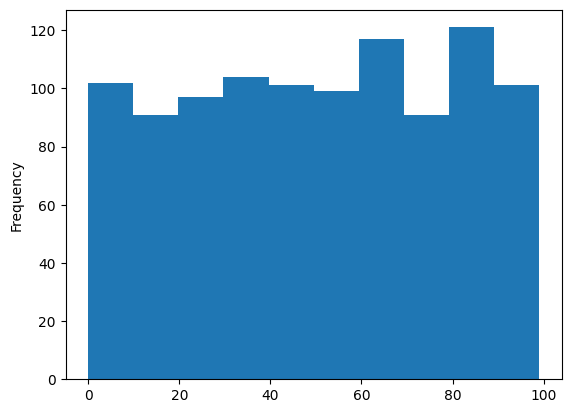

In [6]:
# Free cell for custom interaction (Play around here!)
df[0].plot.hist()

`modin.pandas` is using all of the cores in your machine to read the CSV file much faster than Pandas!

### Concept for Exercise: Identical API

As previously mentioned, `modin.pandas` has an identical API to Pandas. In this section, we will go over some examples of how you can use `modin.pandas` to interact with your data in the same way you would with Pandas.

**Note: `modin.pandas` does not yet have 100% of the Pandas API fully implemented or optimized. Some parameters are not implemented for some methods and some of the more obscure methods are not yet implemented. We are continuing to work toward 100% API coverage.**

For a full list of implemented methods, visit the [Modin documentation](https://modin.readthedocs.io/en/latest/pandas_supported.html).

In [7]:
df.describe()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
count,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.00000,1024.000000,1024.000000,1024.000000,1024.000000,...,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000,1024.000000
mean,50.594727,49.408203,49.674805,49.627930,49.165039,49.02832,48.569336,49.776367,48.999023,49.171875,...,48.407227,49.837891,48.083008,48.317383,49.800781,50.076172,50.001953,50.298828,48.425781,50.337891
std,28.814043,28.859442,28.932468,29.412648,28.305157,29.12343,29.222025,28.720921,29.068985,29.230365,...,29.016448,28.476072,28.580868,28.940156,28.409300,28.702166,28.649498,28.265474,28.701762,28.542042
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.000000,24.750000,24.000000,24.000000,25.000000,23.00000,24.000000,25.000000,23.750000,24.000000,...,23.000000,26.000000,24.000000,23.000000,25.000000,25.000000,25.000000,27.000000,23.000000,26.000000
50%,51.000000,50.000000,49.000000,50.000000,49.000000,50.00000,46.500000,49.000000,49.000000,50.000000,...,47.000000,51.000000,47.000000,48.000000,50.000000,51.000000,49.000000,53.000000,48.000000,52.000000
75%,76.000000,74.000000,74.000000,75.000000,73.000000,74.25000,73.000000,76.000000,75.000000,73.250000,...,75.000000,74.000000,72.000000,73.000000,74.000000,75.000000,75.000000,73.000000,73.000000,75.000000
max,99.000000,99.000000,99.000000,99.000000,99.000000,99.00000,99.000000,99.000000,99.000000,99.000000,...,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000


In [8]:
# Transpose the data
df.T

,0,1,2,3,4,5,6,7,8,9,...,1014,1015,1016,1017,1018,1019,1020,1021,1022,1023
0,81,3,56,57,28,10,67,65,4,86,...,83,64,42,63,23,10,56,74,14,74
1,81,20,87,39,6,36,6,91,69,17,...,70,55,63,23,60,93,97,36,88,66
2,60,66,36,7,21,73,88,0,98,92,...,69,24,10,36,22,38,60,72,46,10
3,97,22,32,85,61,33,2,73,15,84,...,38,29,91,37,56,18,80,29,80,87
4,38,72,34,37,8,0,26,12,86,49,...,92,21,29,98,42,74,52,69,31,71
5,10,95,20,41,49,27,22,86,54,18,...,54,36,93,26,53,63,66,83,35,93
6,81,23,57,73,39,91,53,69,52,85,...,2,32,14,29,97,90,30,88,84,35
7,1,20,39,24,29,21,92,89,83,82,...,25,75,27,98,19,4,46,78,18,2
8,45,35,77,76,70,25,62,46,56,70,...,18,76,63,64,61,55,11,85,12,87
9,68,85,67,9,68,63,61,54,80,58,...,99,84,67,13,71,39,92,1,77,10


In [9]:
# Create a new column the same as Pandas
df['New Column'] = np.nan

In [10]:
df

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,New Column
0,81,81,60,97,38,10,81,1,45,68,...,26,91,20,66,10,73,81,10,22,NaN
1,3,20,66,22,72,95,23,20,35,85,...,83,89,76,26,97,47,95,5,77,NaN
2,56,87,36,32,34,20,57,39,77,67,...,70,0,49,84,6,47,81,35,60,NaN
3,57,39,7,85,37,41,73,24,76,9,...,70,63,54,3,59,27,47,75,66,NaN
4,28,6,21,61,8,49,39,29,70,68,...,98,14,84,3,19,8,29,76,16,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1019,10,93,38,18,74,63,90,4,55,39,...,45,91,45,30,9,46,20,57,33,NaN
1020,56,97,60,80,52,66,30,46,11,92,...,88,16,23,13,26,11,17,36,24,NaN
1021,74,36,72,29,69,83,88,78,85,1,...,18,18,84,5,33,84,61,60,66,NaN
1022,14,88,46,80,31,35,84,18,12,77,...,98,56,83,72,6,46,68,88,97,NaN


In [11]:
df.columns

Index([           0,            1,            2,            3,            4,
                  5,            6,            7,            8,            9,
                 10,           11,           12,           13,           14,
                 15,           16,           17,           18,           19,
                 20,           21,           22,           23,           24,
                 25,           26,           27,           28,           29,
                 30,           31, 'New Column'],
      dtype='object')

In [12]:
# Delete the first column
del df[df.columns[0]]

In [13]:
df.columns

Index([           1,            2,            3,            4,            5,
                  6,            7,            8,            9,           10,
                 11,           12,           13,           14,           15,
                 16,           17,           18,           19,           20,
                 21,           22,           23,           24,           25,
                 26,           27,           28,           29,           30,
                 31, 'New Column'],
      dtype='object')

In [14]:
# Some operation are not yet optimized, but they are implemented.
df.fillna(value=0, axis=0, limit=100)

,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,New Column
0,81,60,97,38,10,81,1,45,68,14,...,26,91,20,66,10,73,81,10,22,0.0
1,20,66,22,72,95,23,20,35,85,88,...,83,89,76,26,97,47,95,5,77,0.0
2,87,36,32,34,20,57,39,77,67,38,...,70,0,49,84,6,47,81,35,60,0.0
3,39,7,85,37,41,73,24,76,9,86,...,70,63,54,3,59,27,47,75,66,0.0
4,6,21,61,8,49,39,29,70,68,72,...,98,14,84,3,19,8,29,76,16,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1019,93,38,18,74,63,90,4,55,39,99,...,45,91,45,30,9,46,20,57,33,NaN
1020,97,60,80,52,66,30,46,11,92,92,...,88,16,23,13,26,11,17,36,24,NaN
1021,36,72,29,69,83,88,78,85,1,97,...,18,18,84,5,33,84,61,60,66,NaN
1022,88,46,80,31,35,84,18,12,77,99,...,98,56,83,72,6,46,68,88,97,NaN


In [15]:
# Some operations are not yet implemented, they will throw this error.
df.kurtosis()

1            -1.198272
2            -1.211582
3            -1.242382
4            -1.136212
5            -1.232468
6            -1.194716
7            -1.217505
8            -1.264712
9            -1.206027
10           -1.138194
11           -1.207129
12           -1.204045
13           -1.200551
14           -1.193578
15           -1.200117
16           -1.188051
17           -1.149774
18           -1.180708
19           -1.176568
20           -1.222195
21           -1.226359
22           -1.224558
23           -1.175082
24           -1.176086
25           -1.212762
26           -1.169402
27           -1.192732
28           -1.177455
29           -1.138732
30           -1.200010
31           -1.171971
New Column         NaN
dtype: float64

In [ ]:
# Free cell for custom interaction (Play around here!).
